PyTorch version: 2.11.0+cpu
Using device: cpu
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 88.6MB/s]


Loaded ResNet50 with 1000 ImageNet classes

Loaded Waddles (a pig): (3840, 2378)
Loaded Mystery Shack totem pole: (1704, 2272)
Loaded Bear in the woods: (2400, 1600)
Could not load Stan's golf cart (429 Client Error: Too Many Requests (015d12c) for url: https://upload.wikimedia.org/wikipedia/commons/8/8e/Yamaha_Drive_2_golf_car.jpg?utm_source=en.wikipedia.org&utm_campaign=api&utm_content=thumbnail_unscaled) - skipping



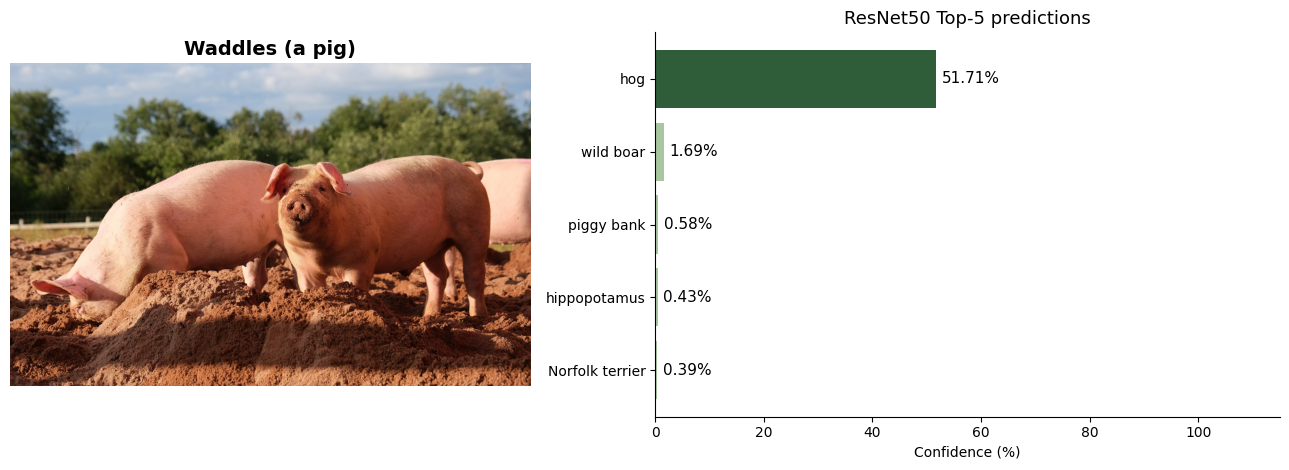

Top-5 predictions for Waddles (a pig):
  hog: 51.71%
  wild boar: 1.69%
  piggy bank: 0.58%
  hippopotamus: 0.43%
  Norfolk terrier: 0.39%



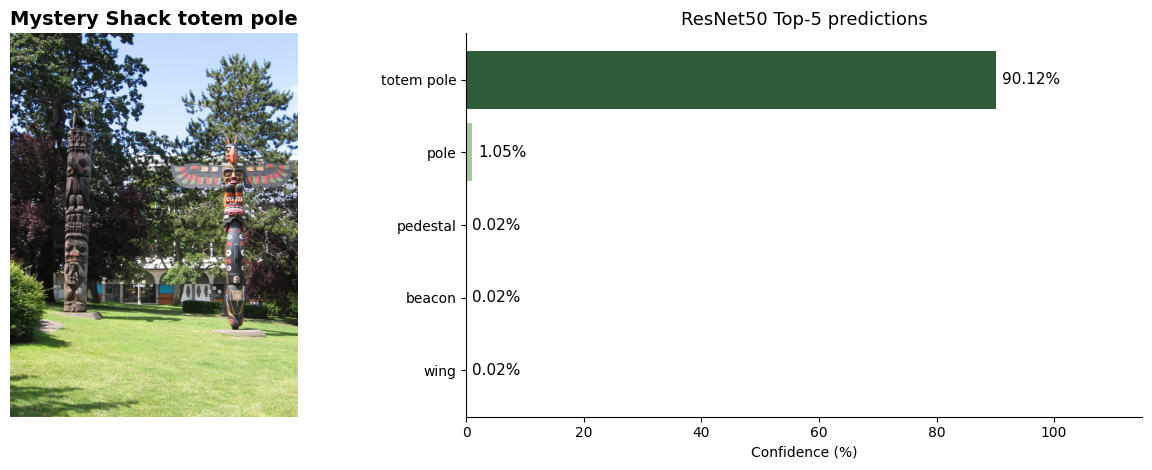

Top-5 predictions for Mystery Shack totem pole:
  totem pole: 90.12%
  pole: 1.05%
  pedestal: 0.02%
  beacon: 0.02%
  wing: 0.02%



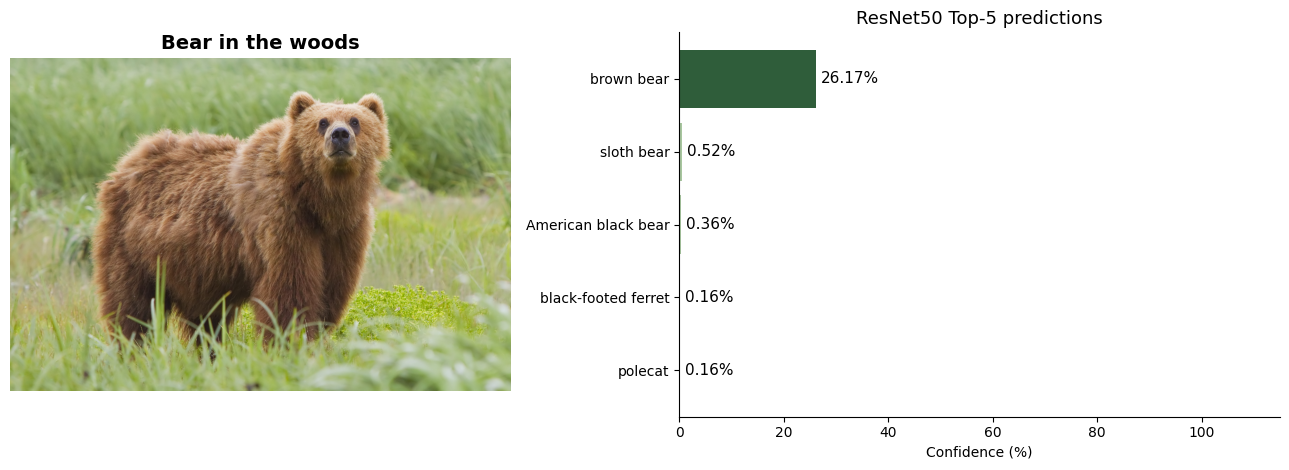

Top-5 predictions for Bear in the woods:
  brown bear: 26.17%
  sloth bear: 0.52%
  American black bear: 0.36%
  black-footed ferret: 0.16%
  polecat: 0.16%

Image                        Top prediction           Confidence
----------------------------------------------------------------
Waddles (a pig)              hog                       51.71%
Mystery Shack totem pole     totem pole                90.12%
Bear in the woods            brown bear                26.17%


In [1]:
import io
import requests
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.models import resnet50, ResNet50_Weights

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# pretrained model
weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights).to(device)
model.eval()
preprocess = weights.transforms()
categories = weights.meta["categories"]
print(f"Loaded ResNet50 with {len(categories)} ImageNet classes\n")

# images
THEMED = {
    "Waddles (a pig)":            "Domestic_pig",
    "Mystery Shack totem pole":   "Totem_pole",
    "Bear in the woods":          "Brown_bear",
    "Stan's golf cart":           "Golf_cart",
}
HEADERS = {"User-Agent": "CS4453-bonus-assignment/1.0 (Google Colab; educational use)"}

def wiki_image(article):
    api = f"https://en.wikipedia.org/api/rest_v1/page/summary/{article}"
    info = requests.get(api, headers=HEADERS, timeout=30).json()
    img_url = (info.get("originalimage") or info.get("thumbnail"))["source"]
    r = requests.get(img_url, headers=HEADERS, timeout=30)
    r.raise_for_status()
    return Image.open(io.BytesIO(r.content)).convert("RGB")

images = {}
for title, article in THEMED.items():
    try:
        images[title] = wiki_image(article)
        print(f"Loaded {title}: {images[title].size}")
    except Exception as e:
        print(f"Could not load {title} ({e}) - skipping")

# Prediction top 5
@torch.no_grad()
def predict_top5(img):
    x = preprocess(img).unsqueeze(0).to(device)
    probs = torch.softmax(model(x)[0], dim=0)
    top_p, top_i = probs.topk(5)
    return [(categories[int(i)], float(p)) for p, i in zip(top_p.cpu(), top_i.cpu())]

def show_predictions(img, preds, title):
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(13, 4.8),
                                         gridspec_kw={"width_ratios": [1, 1.2]})
    ax_img.imshow(img)
    ax_img.axis("off")
    ax_img.set_title(title, fontsize=14, fontweight="bold")

    labels = [n for n, _ in preds][::-1]
    pcts = [p * 100 for _, p in preds][::-1]
    bars = ax_bar.barh(labels, pcts, color=["#a8c69f"] * 4 + ["#2f5d3a"])  # forest greens
    for bar, pct in zip(bars, pcts):
        ax_bar.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
                    f"{pct:.2f}%", va="center", fontsize=11)
    ax_bar.set_xlim(0, 115)
    ax_bar.set_xlabel("Confidence (%)")
    ax_bar.set_title("ResNet50 Top-5 predictions", fontsize=13)
    ax_bar.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

    print(f"Top-5 predictions for {title}:")
    for n, p in preds:
        print(f"  {n}: {p * 100:.2f}%")
    print()

print()
results = {}
for title, img in images.items():
    preds = predict_top5(img)
    results[title] = preds
    show_predictions(img, preds, title)

print(f"{'Image':<28} {'Top prediction':<24} Confidence")
print("-" * 64)
for title, preds in results.items():
    label, p = preds[0]
    print(f"{title:<28} {label:<24} {p * 100:6.2f}%")